## Name: Atishay Choudhary

### Roll no.: 2023BTCSE004

### Program: B.Tech (CSE)

### Couse: Soft Computing - STDA2102


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl


Exercise 1: Simple fuzzy set 'Tall'
{150: 0.0, 160: 0.2, 170: 0.5, 180: 0.8, 190: 1.0}


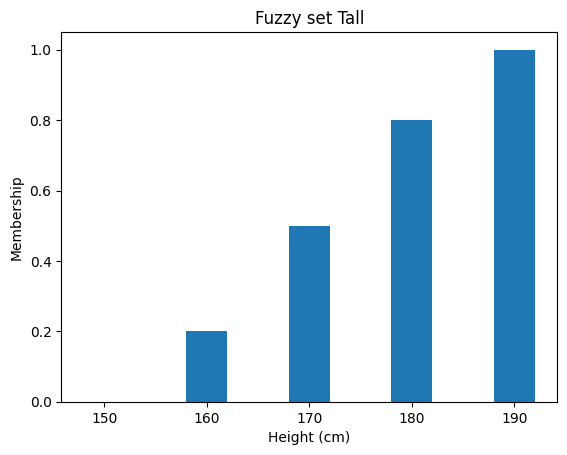

In [3]:
# 1. Simple fuzzy set using membership values
print("\nExercise 1: Simple fuzzy set 'Tall'")
tall = {150: 0.0, 160: 0.2, 170: 0.5, 180: 0.8, 190: 1.0}
print(tall)
plt.bar(list(tall.keys()), list(tall.values()), width=4)
plt.title("Fuzzy set Tall")
plt.xlabel("Height (cm)")
plt.ylabel("Membership")
plt.show()


Exercise 2: Membership functions


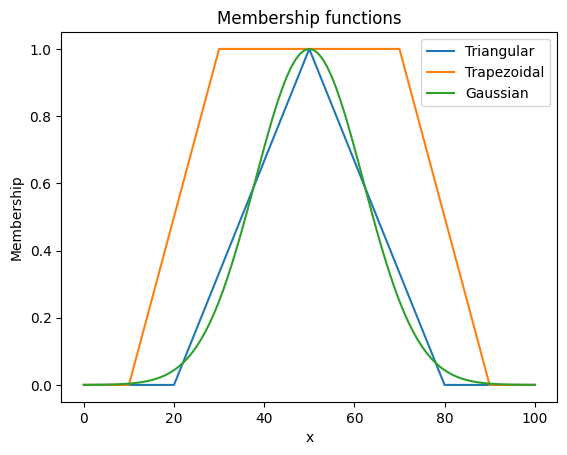

In [4]:
# 2. Triangular, Trapezoidal and Gaussian membership functions
print("\nExercise 2: Membership functions")
x = np.arange(0, 101)
plt.plot(x, fuzz.trimf(x, [20, 50, 80]), label="Triangular")
plt.plot(x, fuzz.trapmf(x, [10, 30, 70, 90]), label="Trapezoidal")
plt.plot(x, fuzz.gaussmf(x, 50, 12), label="Gaussian")
plt.title("Membership functions")
plt.xlabel("x")
plt.ylabel("Membership")
plt.legend()
plt.show()


Exercise 3: Fuzzy set operations
A          : [0.   0.33 0.67 1.   0.67 0.33 0.   0.   0.   0.   0.  ]
B          : [0.   0.   0.   0.   0.   0.33 0.67 1.   0.67 0.33 0.  ]
Union      : [0.   0.33 0.67 1.   0.67 0.33 0.67 1.   0.67 0.33 0.  ]
Intersect  : [0.   0.   0.   0.   0.   0.33 0.   0.   0.   0.   0.  ]
Complement A: [1.   0.67 0.33 0.   0.33 0.67 1.   1.   1.   1.   1.  ]


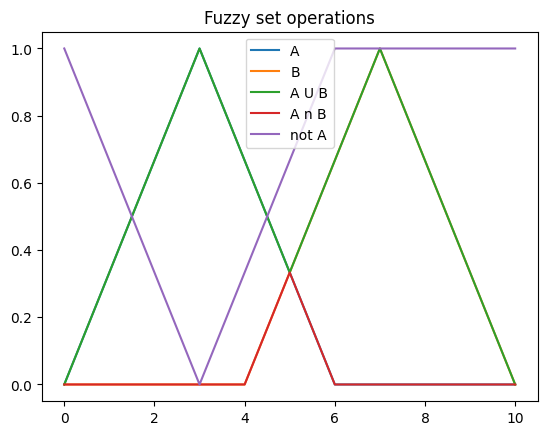

In [5]:
# 3. Union, Intersection and Complement
print("\nExercise 3: Fuzzy set operations")
x = np.arange(0, 11)
A = fuzz.trimf(x, [0, 3, 6])
B = fuzz.trimf(x, [4, 7, 10])
_, union = fuzz.fuzzy_or(x, A, x, B)
_, inter = fuzz.fuzzy_and(x, A, x, B)
comp = fuzz.fuzzy_not(A)
print("A          :", np.round(A, 2))
print("B          :", np.round(B, 2))
print("Union      :", np.round(union, 2))
print("Intersect  :", np.round(inter, 2))
print("Complement A:", np.round(comp, 2))
for data, name in [(A, "A"), (B, "B"), (union, "A U B"),
                   (inter, "A n B"), (comp, "not A")]:
    plt.plot(x, data, label=name)
plt.title("Fuzzy set operations")
plt.legend()
plt.show()


Exercise 4: Fuzzy relation R = A x B (min)
[[0.2 0.2 0.2]
 [0.3 0.5 0.5]
 [0.3 0.7 0.8]
 [0.3 0.7 1. ]]


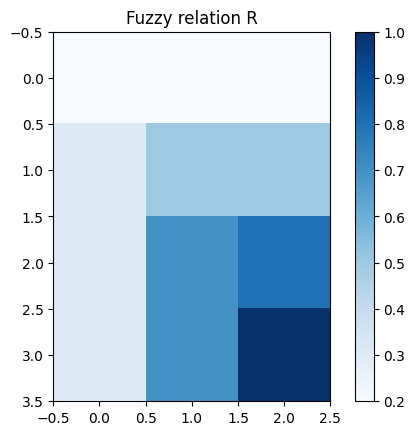

In [6]:
# 4. Fuzzy relation between two fuzzy sets
print("\nExercise 4: Fuzzy relation R = A x B (min)")
A = np.array([0.2, 0.5, 0.8, 1.0])
B = np.array([0.3, 0.7, 1.0])
R = np.minimum.outer(A, B)
print(R)
plt.imshow(R, cmap="Blues")
plt.colorbar()
plt.title("Fuzzy relation R")
plt.show()


Exercise 5: Linguistic variable Temperature


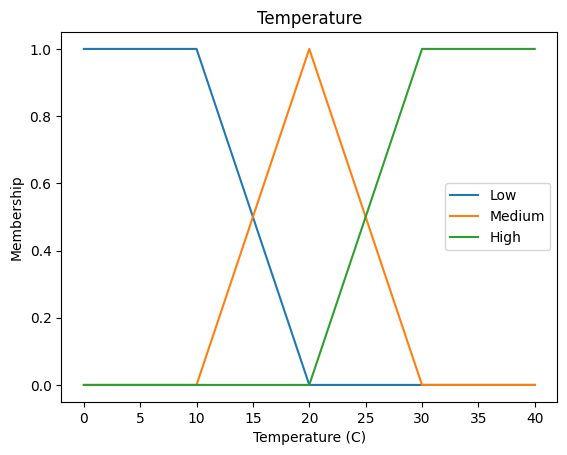

5 C -> Low: 1.00, Medium: 0.00, High: 0.00
22 C -> Low: 0.00, Medium: 0.80, High: 0.20
35 C -> Low: 0.00, Medium: 0.00, High: 1.00


In [7]:
# 5. Linguistic variable: Low, Medium, High
print("\nExercise 5: Linguistic variable Temperature")
t = np.arange(0, 41)
low = fuzz.trapmf(t, [0, 0, 10, 20])
medium = fuzz.trimf(t, [10, 20, 30])
high = fuzz.trapmf(t, [20, 30, 40, 40])
plt.plot(t, low, label="Low")
plt.plot(t, medium, label="Medium")
plt.plot(t, high, label="High")
plt.title("Temperature")
plt.xlabel("Temperature (C)")
plt.ylabel("Membership")
plt.legend()
plt.show()
for v in [5, 22, 35]:
    print(v, "C -> Low: %.2f, Medium: %.2f, High: %.2f" % (
        fuzz.interp_membership(t, low, v),
        fuzz.interp_membership(t, medium, v),
        fuzz.interp_membership(t, high, v)))

In [8]:
# 6. Fuzzy IF-THEN rules for decision making
print("\nExercise 6: Fuzzy IF-THEN rules")
m = np.arange(0, 101)
marks_low = fuzz.trapmf(m, [0, 0, 30, 60])
marks_high = fuzz.trapmf(m, [40, 70, 100, 100])
att_low = fuzz.trapmf(m, [0, 0, 30, 60])
att_high = fuzz.trapmf(m, [40, 70, 100, 100])
marks, att = 72, 45
ml = fuzz.interp_membership(m, marks_low, marks)
mh = fuzz.interp_membership(m, marks_high, marks)
al = fuzz.interp_membership(m, att_low, att)
ah = fuzz.interp_membership(m, att_high, att)
decision = {
    "Pass": min(mh, ah),    # R1: IF marks High AND attendance High THEN Pass
    "Review": min(mh, al),  # R2: IF marks High AND attendance Low THEN Review
    "Fail": ml,             # R3: IF marks Low THEN Fail
}
print("Marks = %d, Attendance = %d" % (marks, att))
print(decision)
print("Decision:", max(decision, key=decision.get))


Exercise 6: Fuzzy IF-THEN rules
Marks = 72, Attendance = 45
{'Pass': np.float64(0.16666666666666666), 'Review': np.float64(0.5), 'Fail': np.float64(0.0)}
Decision: Review



Exercise 7: Mamdani FIS
Tip = 19.85 %


c:\Users\atish\AppData\Local\Programs\Python\Python312\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


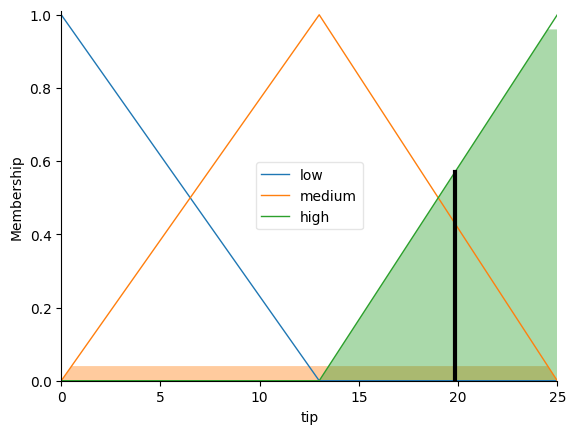

In [9]:
# 7. Mamdani Fuzzy Inference System
print("\nExercise 7: Mamdani FIS")
quality = ctrl.Antecedent(np.arange(0, 11), "quality")
service = ctrl.Antecedent(np.arange(0, 11), "service")
tip = ctrl.Consequent(np.arange(0, 26), "tip")
quality.automf(3, names=["poor", "average", "good"])
service.automf(3, names=["poor", "average", "good"])
tip["low"] = fuzz.trimf(tip.universe, [0, 0, 13])
tip["medium"] = fuzz.trimf(tip.universe, [0, 13, 25])
tip["high"] = fuzz.trimf(tip.universe, [13, 25, 25])
rules = [
    ctrl.Rule(quality["poor"] | service["poor"], tip["low"]),
    ctrl.Rule(service["average"], tip["medium"]),
    ctrl.Rule(service["good"] | quality["good"], tip["high"]),
]
sim = ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))
sim.input["quality"] = 6.5
sim.input["service"] = 9.8
sim.compute()
print("Tip = %.2f %%" % sim.output["tip"])
tip.view(sim=sim)
plt.show()

In [10]:
# 8. Sugeno Fuzzy Inference System (zero order)
print("\nExercise 8: Sugeno FIS")
u = np.arange(0, 10.1, 0.1)
poor = fuzz.trimf(u, [0, 0, 5])
average = fuzz.trimf(u, [0, 5, 10])
good = fuzz.trimf(u, [5, 10, 10])
mu = lambda mf, v: fuzz.interp_membership(u, mf, v)
s, q = 9.8, 6.5
w = np.array([max(mu(poor, s), mu(poor, q)),   # R1: poor  -> z = 5
              mu(average, s),                  # R2: average -> z = 15
              max(mu(good, s), mu(good, q))])  # R3: good  -> z = 25
z = np.array([5, 15, 25])
print("Firing strengths:", np.round(w, 2))
print("Tip = %.2f %%" % (np.sum(w * z) / np.sum(w)))


Exercise 8: Sugeno FIS
Firing strengths: [0.   0.04 0.96]
Tip = 24.60 %



Exercise 9: Defuzzification
Centroid         = 14.230
Bisector         = 14.271
Mean of Maximum  = 16.236


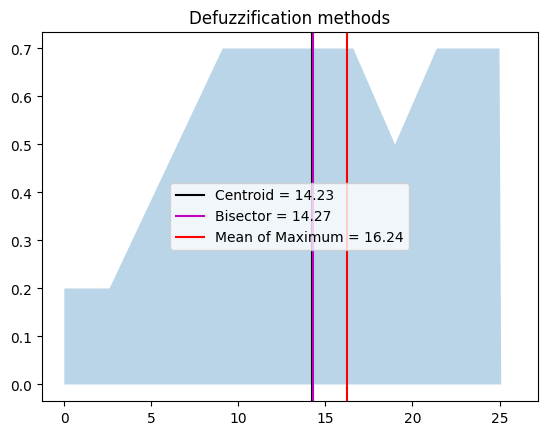

In [11]:
# 9. Defuzzification methods
print("\nExercise 9: Defuzzification")
x = np.arange(0, 26, 0.1)
aggregated = np.fmax(np.fmin(0.2, fuzz.trimf(x, [0, 0, 13])),
                     np.fmax(np.fmin(0.7, fuzz.trimf(x, [0, 13, 25])),
                             np.fmin(0.7, fuzz.trimf(x, [13, 25, 25]))))
plt.fill_between(x, aggregated, alpha=0.3)
for name, key in [("Centroid", "centroid"), ("Bisector", "bisector"),
                  ("Mean of Maximum", "mom")]:
    val = fuzz.defuzz(x, aggregated, key)
    print("%-16s = %.3f" % (name, val))
    plt.axvline(val, label="%s = %.2f" % (name, val),
                color={"centroid": "k", "bisector": "m", "mom": "r"}[key])
plt.title("Defuzzification methods")
plt.legend()
plt.show()


Exercise 10: Fuzzy Logic Controller
Temp = 10 C, Humidity = 30 % -> Power = 16.7 %
Temp = 25 C, Humidity = 80 % -> Power = 50.0 %
Temp = 36 C, Humidity = 85 % -> Power = 83.3 %


c:\Users\atish\AppData\Local\Programs\Python\Python312\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:125: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


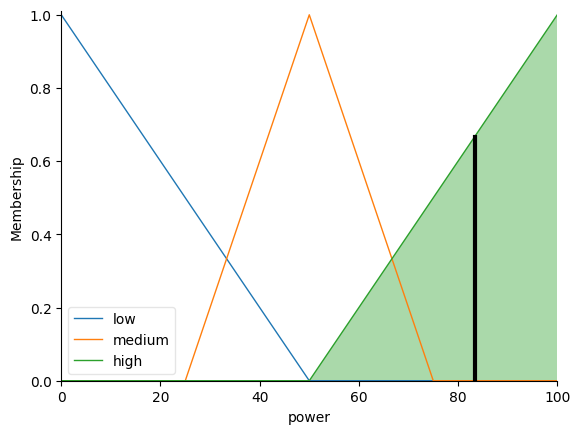

In [12]:
# 10. Fuzzy Logic Controller: air conditioner power
print("\nExercise 10: Fuzzy Logic Controller")
temp = ctrl.Antecedent(np.arange(0, 41), "temp")
hum = ctrl.Antecedent(np.arange(0, 101), "hum")
power = ctrl.Consequent(np.arange(0, 101), "power")
temp["cold"] = fuzz.trapmf(temp.universe, [0, 0, 10, 22])
temp["warm"] = fuzz.trimf(temp.universe, [15, 25, 35])
temp["hot"] = fuzz.trapmf(temp.universe, [28, 34, 40, 40])
hum["dry"] = fuzz.trapmf(hum.universe, [0, 0, 25, 55])
hum["humid"] = fuzz.trapmf(hum.universe, [40, 70, 100, 100])
power["low"] = fuzz.trimf(power.universe, [0, 0, 50])
power["medium"] = fuzz.trimf(power.universe, [25, 50, 75])
power["high"] = fuzz.trimf(power.universe, [50, 100, 100])
rules = [
    ctrl.Rule(temp["cold"], power["low"]),
    ctrl.Rule(temp["warm"] & hum["dry"], power["low"]),
    ctrl.Rule(temp["warm"] & hum["humid"], power["medium"]),
    ctrl.Rule(temp["hot"] & hum["dry"], power["medium"]),
    ctrl.Rule(temp["hot"] & hum["humid"], power["high"]),
]
flc = ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))
for t_in, h_in in [(10, 30), (25, 80), (36, 85)]:
    flc.input["temp"] = t_in
    flc.input["hum"] = h_in
    flc.compute()
    print("Temp = %d C, Humidity = %d %% -> Power = %.1f %%"
          % (t_in, h_in, flc.output["power"]))
power.view(sim=flc)
plt.show()